# Estimadores de cohorte, de duración y de Aalen-Johansen sobre CEREP

**Pregunta:** Cuando las tablas anuales no muestran ningún incumplimiento en un grado delgado, ¿su PD es realmente cero, y cuál estimador (de cohorte, de duración, de Aalen-Johansen o EM) se acerca más a la PD verdadera cuando la verdad se conoce?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 01 de este tema (cohortes, la PD a un año y el promedio de largo plazo)
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este notebook puedes:

- agrupar las tablas anuales de cohortes en una matriz con el estimador de Anderson y Goodman y poner tres intervalos (Wald, Agresti-Coull, Jeffreys) a la PD de un grado delgado;
- decir qué no puede ver el estimador de cohorte (lo que ocurre dentro del año) y qué usa en su lugar el estimador de duración (cada salto y el tiempo pasado en cada grado);
- calcular un generador de duración, una matriz de Aalen-Johansen y un generador EM sobre un conjunto de trayectorias de calificación cuyo generador verdadero se conoce, y leer cada uno contra la verdad;
- explicar por qué el estimador de duración da una PD distinta de cero a un grado donde el estimador de cohorte no vio incumplimientos;
- leer la evidencia de 200 simulaciones sobre cuán seguido cada estimador devuelve exactamente cero y qué tan grande es su error.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.generators.paths import RatingPaths
from riskvalidation.transitions import embedding, estimators, intervals
from riskvalidation.transitions.em import em_generator
from scipy.linalg import expm

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Cuatro archivos versionados del caso C04, todos derivados de la publicación CEREP de ESMA (clase de licencia `mirror-allowed`; https://registers.esma.europa.eu/cerep-publication/):

- `data/derived/C04/sp.json`: las cohortes anuales de S&P (26 tablas, 2000 a 2025), la matriz agrupada y los generadores.
- `data/derived/C04/fitch.json`: lo mismo para Fitch (24 cohortes anuales), para comparar entre agencias.
- `data/derived/C04/models-transitions.json`: el generador que el caso ajustó a los conteos de S&P por EM (`fit.generator.q`) y el número de deudores desde el que simula (`fit.generator.obligors`). Este generador es la **verdad conocida** de la segunda mitad del notebook.
- `data/derived/C04/markov.json`: el estudio de simulación versionado, 200 conjuntos de datos con semilla sacados de ese generador, con el sesgo y el error de seis estimadores.

CEREP publica instantáneas (las calificaciones al 1 de enero y al 31 de diciembre), nunca trayectorias individuales, así que los estimadores de tiempo continuo no se pueden correr sobre las tablas reales: necesitan la fecha de cada salto. Por eso el notebook saca **un** conjunto de trayectorias desde el generador versionado con el `RatingPaths` del motor: es pequeño (una fracción de segundo), tiene semilla, y cada estimador se puede comparar con el generador que lo hizo.

La celda siguiente carga los archivos e imprime lo que contienen.

In [2]:
# Cargar los cuatro artefactos (el notebook está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
C04 = ROOT / "data" / "derived" / "C04"
load = lambda name: json.loads((C04 / name).read_text(encoding="utf-8"))
sp, fitch = load("sp.json"), load("fitch.json")
models, markov = load("models-transitions.json"), load("markov.json")
out = sp["outputs"]
grades, states = out["grades"], out["states"]
cohorts = out["cohorts"]

print("cohortes anuales de S&P:", len(cohorts), "| Fitch:", len(fitch["outputs"]["cohorts"]))
print("deudores que simula el generador verdadero, por grado:",
      models["fit"]["generator"]["obligors"])
print("estudio de simulación: simulaciones:", markov["outputs"]["design"]["reps"],
      "| años:", markov["outputs"]["design"]["years"])

cohortes anuales de S&P: 26 | Fitch: 24
deudores que simula el generador verdadero, por grado: [75, 822, 1814, 1756, 1054, 1391, 201]
estudio de simulación: simulaciones: 200 | años: 5


## Método

### Paso 1: agrupar las cohortes anuales

Una cohorte da a cada grado unos cientos de calificaciones, y una transición rara puede no aparecer en ella. Anderson y Goodman (1957, ecuación 2.8) agrupan los períodos bajo homogeneidad en el tiempo: suman las entradas correspondientes de las tablas de conteos y dividen cada fila por su total,

$$\hat p_{ij} = \frac{\sum_t N_{ij}(t)}{\sum_t \sum_k N_{ik}(t)}$$

Primero se quitan las calificaciones retiradas de cada año (el tratamiento de la industria del notebook 01). Los años con más calificaciones pesan más, por lo que la tasa agrupada no es el promedio de las tasas anuales del notebook 01.

La celda siguiente llama al `pooled_cohort` del motor sobre las 26 tablas e imprime, por grado, las calificaciones agrupadas, los incumplimientos entre ellas y la PD agrupada.

In [3]:
# Agrupar las 26 tablas anuales con el motor, quitando las retiradas año por año
tables = [np.vstack([np.array(c["counts"], dtype=float), np.zeros(len(states))]) for c in cohorts]
gone = [np.append(np.array(c["withdrawn"], dtype=float), 0.0) for c in cohorts]
pooled = estimators.pooled_cohort(tables, gone, treatment="exclude")
defaults = pooled["counts"][:7, -1]
ratings = pooled["row_sizes"][:7]

print(f"{'grado':8s}{'calificaciones':>22s}{'incumplimientos':>16s}{'PD agrupada':>14s}")
for g in range(7):
    print(f"{grades[g]:8s}{ratings[g]:22.0f}{defaults[g]:16.0f}{100 * pooled['matrix'][g, -1]:13.4f}%")

grado           calificaciones incumplimientos   PD agrupada
AAA                       1895               0       0.0000%
AA                       20192               1       0.0050%
A                        45073              13       0.0288%
BBB                      42854              35       0.0817%
BB                       24842              86       0.3462%
B                        31712             372       1.1731%
CCC-C                     3731             301       8.0675%


### Paso 2: un intervalo sobre un grado delgado

La PD agrupada de AA descansa en un incumplimiento en unas veinte mil calificaciones, y la de AAA en ninguno. Una estimación puntual no dice nada de eso. El motor ofrece tres intervalos al 95%, todos en `transitions.intervals`: el intervalo de Wald $\hat p \pm z\sqrt{\hat p(1-\hat p)/n}$, el de Agresti-Coull, que agrega $z^2$ pseudo-observaciones antes de aplicar la fórmula de Wald, y el intervalo de Jeffreys de colas iguales, los cuantiles de $\mathrm{Beta}(D + \tfrac12,\, n - D + \tfrac12)$ (Brown, Cai y DasGupta, 2001). Schuermann y Hanson (2004) usan los dos primeros para las PD por grado.

La celda siguiente llama a los tres sobre los incumplimientos y las calificaciones agrupadas del paso anterior e imprime la cota superior que cada uno pone a la PD de los cuatro mejores grados.

In [4]:
# Los tres intervalos de 95% del motor sobre los incumplimientos y las calificaciones agrupadas
wald = intervals.pd_wald(defaults, ratings, level=0.95)
agresti = intervals.pd_agresti_coull(defaults, ratings, level=0.95)
jeffreys = intervals.pd_jeffreys(defaults, ratings, level=0.95)
bands = {"Wald": wald, "Agresti-Coull": agresti, "Jeffreys": jeffreys}

print(f"{'grado':8s}{'incumplim.':>14s}" + "".join(f"{k:>22s}" for k in bands))
for g in range(4):
    cells = [f"{100 * b['lower'][g]:.3f}% a {100 * b['upper'][g]:.3f}%" for b in bands.values()]
    print(f"{grades[g]:8s}{defaults[g]:14.0f}" + "".join(f"{c:>22s}" for c in cells))

grado       incumplim.                  Wald         Agresti-Coull              Jeffreys
AAA                  0       0.000% a 0.000%       0.000% a 0.244%       0.000% a 0.132%
AA                   1       0.000% a 0.015%       0.000% a 0.031%       0.001% a 0.023%
A                   13       0.013% a 0.045%       0.016% a 0.050%       0.016% a 0.048%
BBB                 35       0.055% a 0.109%       0.058% a 0.114%       0.058% a 0.112%


La celda siguiente dibuja la cota superior de cada intervalo para los cuatro mejores grados, con su valor escrito sobre la barra.

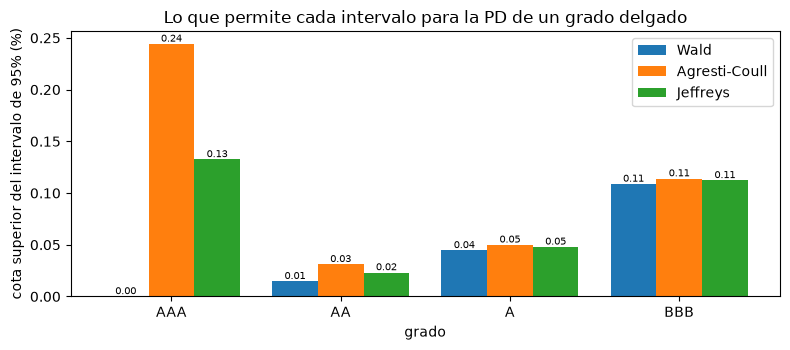

In [5]:
# Dibujar la cota superior de los tres intervalos para AAA, AA, A y BBB
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(4)
for k, (name, band) in enumerate(bands.items()):
    heights = 100 * band["upper"][:4]
    ax.bar(x + (k - 1) * 0.27, heights, 0.27, label=name)
    for xi, h in zip(x + (k - 1) * 0.27, heights):
        ax.text(xi, h, f"{h:.2f}", ha="center", va="bottom", fontsize=7)
ax.set_xticks(x)
ax.set_xticklabels(grades[:4])
ax.set_xlabel("grado")
ax.set_ylabel("cota superior del intervalo de 95% (%)")
ax.set_title("Lo que permite cada intervalo para la PD de un grado delgado")
ax.legend()
fig.tight_layout()
plt.show()

AAA tiene 1.895 calificaciones agrupadas y ningún incumplimiento, y el intervalo de Wald lo convierte en una cota superior exactamente cero: el estimador está seguro de una PD que no descansa en nada. Agresti-Coull y Jeffreys mantienen una cota superior de 0,244% y 0,132%, que es la afirmación honesta de que ningún incumplimiento en 1.895 calificaciones es compatible con una PD de unas centésimas de punto porcentual. Para AA los tres intervalos coinciden dentro de un factor de dos; de A hacia abajo son parecidos. La figura no puede decir cuál intervalo cubre la verdad con más frecuencia cuando el grado es delgado; eso requiere una verdad conocida, que es lo que construyen los pasos siguientes.

### Paso 3: un conjunto de datos cuya verdad se conoce

El generador que el caso ajustó a los conteos de S&P es la verdad aquí: un generador válido $Q$ cuya PD a un año por grado es la columna de incumplimiento de $\exp(Q)$. La celda siguiente lo lee de `models-transitions.json`, verifica con el motor que es un generador (entradas fuera de la diagonal no negativas, filas que suman cero, incumplimiento absorbente) e imprime la PD verdadera a un año y el tiempo medio que un deudor pasa en cada grado antes de dejarlo, $-1/q_{ii}$.

In [6]:
# Leer el generador verdadero, preguntar al motor si lo es y calcular su PD a un año
q_true = np.array(models["fit"]["generator"]["q"], dtype=float)
n_obligors = tuple(models["fit"]["generator"]["obligors"])
pd_true = expm(q_true)[:7, -1]
dwell = -1.0 / np.diag(q_true)[:7]

print("generador válido:", embedding.is_generator(q_true))
print(f"{'grado':8s}{'PD verdadera':>16s}{'años medios en el grado':>32s}")
for g in range(7):
    print(f"{grades[g]:8s}{100 * pd_true[g]:15.4f}%{dwell[g]:32.2f}")

generador válido: True
grado       PD verdadera         años medios en el grado
AAA              0.0066%                            5.12
AA               0.0049%                            8.51
A                0.0288%                           15.69
BBB              0.0817%                           13.36
BB               0.3462%                            7.22
B                1.1731%                            6.59
CCC-C            8.0618%                            2.89


`RatingPaths` sortea, con una semilla fija, la trayectoria de calificación de cada deudor durante cinco años, observada en fotos anuales como CEREP. El sorteo es exacto: el motor simula la cadena en tiempo continuo, así que las trayectorias guardan la fecha de cada salto, algo que una tabla real de CEREP no tiene. CEREP publica fotos, nunca trayectorias individuales, así que los estimadores de tiempo continuo no pueden correr sobre las tablas reales, y este sorteo es lo que permite que cada estimador se enfrente a un generador que lo produjo.

In [7]:
# Sortear un conjunto de trayectorias de calificación con semilla, observadas en fotos anuales
snapshots = tuple(float(t) for t in range(6))
generator = RatingPaths(q_true, n_obligors, horizon=5.0, snapshots=snapshots)
data = generator.draw(np.random.default_rng(20261021))
segments, steps = data["segments"], data["steps"]

print("deudores:", int(sum(n_obligors)))
print("tramos (uno por permanencia en un grado):", len(segments["obligor"]))
print("tablas de fotos anuales:", len(steps))

deudores: 7113
tramos (uno por permanencia en un grado): 10953
tablas de fotos anuales: 5


### Paso 4: el estimador de cohorte frente al estimador de duración

Sobre los mismos deudores, dos lecturas. El estimador de cohorte ve solo las cinco instantáneas anuales: las agrupa con la ecuación 2.8 y lee la columna de incumplimiento. El estimador de duración (Lando y Skodeberg, 2002) usa cada salto y el tiempo que cada deudor pasó en cada grado. Para una cadena homogénea en el tiempo observada de forma continua, la verosimilitud se maximiza con

$$\hat q_{ij} = \frac{K_{ij}}{S_i}, \quad i \neq j, \qquad \hat q_{ii} = -\sum_{j \neq i} \hat q_{ij}$$

con $K_{ij}$ el número de saltos observados de $i$ a $j$ y $S_i$ el tiempo total pasado en $i$; la matriz a un año es $P = \exp(\hat Q)$. Una calificación puede ir de AAA a AA, a A, ... hasta el incumplimiento dentro de un año, y el estimador de duración ve cada paso, mientras que una instantánea ve solo el comienzo y el final.

La celda siguiente corre ambos sobre el sorteo, imprime los saltos desde AAA y el tiempo pasado en cada grado, y pone las dos PD junto a la verdad.

In [8]:
# El generador de duración desde las trayectorias (K/S) y el estimador de cohorte agrupado desde las cinco fotos
dur = estimators.duration_generator(segments, len(states))
q_dur = dur["generator"]
cohort_5 = estimators.pooled_cohort([s["counts"] for s in steps])
pd_cohort = cohort_5["matrix"][:7, -1]
pd_dur = expm(q_dur)[:7, -1]

print("saltos desde AAA, a AAA ... D:", np.array(dur["jumps"])[0].astype(int))
print("años-deudor en cada grado:", np.round(np.array(dur["holding"])[:7], 1))
print(f"{'grado':8s}{'verdad':>12s}{'cohorte':>12s}{'duración':>12s}{'incumpl. vistos':>20s}")
for g in range(7):
    print(f"{grades[g]:8s}{100 * pd_true[g]:11.4f}%{100 * pd_cohort[g]:11.4f}%"
          f"{100 * pd_dur[g]:11.4f}%{cohort_5['counts'][g, -1]:20.0f}")

saltos desde AAA, a AAA ... D: [ 0 54  0  0  0  1  1  0]
años-deudor en cada grado: [ 240.2 3674.1 9263.6 8977.5 5090.  6432.9 1313.1]
grado         verdad     cohorte    duración     incumpl. vistos
AAA          0.0066%     0.0000%     0.0204%                   0
AA           0.0049%     0.0000%     0.0013%                   0
A            0.0288%     0.0217%     0.0257%                   2
BBB          0.0817%     0.0895%     0.0932%                   8
BB           0.3462%     0.4480%     0.4808%                  23
B            1.1731%     1.3231%     1.2517%                  86
CCC-C        8.0618%     8.7678%     8.9439%                 111


La celda siguiente dibuja cada estimación como múltiplo de la PD verdadera de su grado, de modo que una línea en uno es una estimación perfecta.

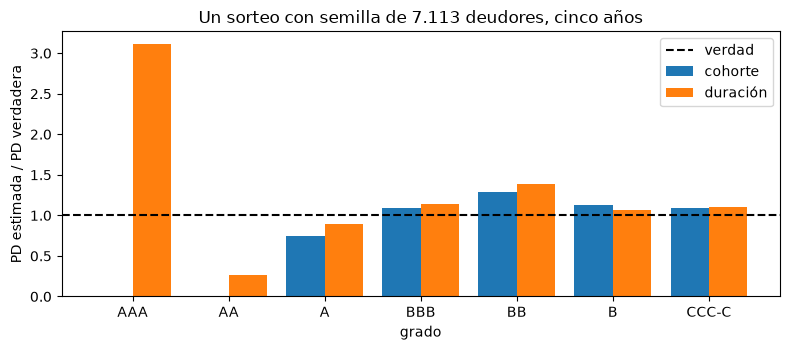

In [9]:
# Dibujar las estimaciones de cohorte y de duración como múltiplos de la PD verdadera, por grado
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(7)
ax.bar(x - 0.2, pd_cohort / pd_true, 0.4, color="tab:blue", label="cohorte")
ax.bar(x + 0.2, pd_dur / pd_true, 0.4, color="tab:orange", label="duración")
ax.axhline(1.0, color="black", linestyle="--", label="verdad")
ax.set_xticks(x)
ax.set_xticklabels(grades)
ax.set_xlabel("grado")
ax.set_ylabel("PD estimada / PD verdadera")
ax.set_title("Un sorteo con semilla de 7.113 deudores, cinco años")
ax.legend()
fig.tight_layout()
plt.show()

Ningún estimador vio un incumplimiento de AAA: la cuenta de saltos desde AAA hacia el incumplimiento es cero. El estimador de cohorte lee entonces exactamente cero para AAA y AA, mientras el estimador de duración vio deudores AAA saltar a B y a CCC-C dentro del año, y la exponencial de la matriz encadena esos saltos con las tasas de incumplimiento de B y CCC-C, así que devuelve una PD positiva: 0,0204% para AAA frente a un 0,0066% verdadero. Un sorteo es una muestra, así que el número de duración puede quedar sobre o bajo la verdad, aquí sobre para AAA y bajo para AA. La figura muestra quién puede equivocarse en qué dirección; el tamaño del error típico necesita muchos sorteos, que es el Paso 7.

### Paso 5: Aalen-Johansen, sin homogeneidad en el tiempo

El estimador de duración supone un solo generador para todo el período. Aalen y Johansen (1978) lo abandonan: estiman la matriz de transición entre dos fechas $s < t$ como el producto, sobre los instantes de salto observados $u$ en $(s, t]$, de la identidad más el incremento de Nelson-Aalen,

$$\hat P(s, t) = \prod_{s < u \le t} \bigl(I + d\hat A(u)\bigr), \qquad d\hat A_{ij}(u) = \frac{dN_{ij}(u)}{Y_i(u-)}$$

con $dN_{ij}(u)$ los saltos de $i$ a $j$ en $u$ y $Y_i(u-)$ los deudores en $i$ justo antes de $u$. No necesita generador ni homogeneidad, y siendo un producto en el tiempo cumple exactamente la identidad de Chapman-Kolmogorov $\hat P(0, 2) = \hat P(0, 1)\,\hat P(1, 2)$.

La celda siguiente calcula las matrices del primero, del segundo y de los dos primeros años, imprime la mayor brecha en la identidad de Chapman-Kolmogorov y pone las PD a un año de los dos años sueltos junto a la verdad y a la estimación de duración.

In [10]:
# Matrices de Aalen-Johansen sobre las mismas trayectorias y la PD que dan para cada año suelto
aj01 = estimators.aalen_johansen(segments, len(states), 0.0, 1.0)["matrix"]
aj12 = estimators.aalen_johansen(segments, len(states), 1.0, 2.0)["matrix"]
aj02 = estimators.aalen_johansen(segments, len(states), 0.0, 2.0)["matrix"]
gap = float(np.abs(aj02 - aj01 @ aj12).max())

print("mayor brecha entre P(0,2) y P(0,1) P(1,2):", f"{gap:.1e}")
print(f"{'grado':8s}{'verdad':>12s}{'AJ P(0,1)':>12s}{'AJ P(1,2)':>12s}{'duración':>12s}")
for g in range(7):
    print(f"{grades[g]:8s}{100 * pd_true[g]:11.4f}%{100 * aj01[g, -1]:11.4f}%"
          f"{100 * aj12[g, -1]:11.4f}%{100 * pd_dur[g]:11.4f}%")

mayor brecha entre P(0,2) y P(0,1) P(1,2): 1.1e-15
grado         verdad   AJ P(0,1)   AJ P(1,2)    duración
AAA          0.0066%     0.0956%     0.0001%     0.0204%
AA           0.0049%     0.0005%     0.0027%     0.0013%
A            0.0288%     0.0081%     0.0604%     0.0257%
BBB          0.0817%     0.0178%     0.1324%     0.0932%
BB           0.3462%     0.5330%     0.6910%     0.4808%
B            1.1731%     1.5360%     1.3384%     1.2517%
CCC-C        8.0618%     7.7028%    10.0631%     8.9439%


El producto de las matrices del primer y del segundo año iguala a la matriz de los dos años salvo redondeo, como dice la definición. Los dos años sueltos difieren entre sí y de la verdad porque son dos muestras de una misma cadena (el generador es homogéneo en el tiempo aquí), que es el ruido que el estudio de 200 simulaciones del Paso 7 promedia. Con una cadena que cambia en el tiempo las dos columnas diferirían por una razón, y solo Aalen-Johansen la seguiría. También muestra su costo: con un año de datos una transición rara es tan delgada para Aalen-Johansen como para el estimador de cohorte, y el de duración es más estable porque agrupa ambos años bajo un solo generador.

### Paso 6: el generador EM, solo desde fotos

Un usuario de CEREP no tiene fechas de salto, solo las tablas anuales. Bladt y Sorensen (2005), como lo presentan Smith y dos Reis (2018), dan un generador por esperanza-maximización: encuentra el generador cuya exponencial de matriz hace más verosímiles los conteos de instantáneas observados, y el resultado es un generador válido por construcción. El `em_generator` del motor recibe la secuencia de tablas de conteos con el largo de cada paso.

La celda siguiente lo corre dos veces: sobre las cinco tablas de fotos del sorteo, donde la verdad se conoce, y sobre las 26 cohortes reales de S&P.

In [11]:
# Generador EM sobre las fotos simuladas y sobre las 26 cohortes reales de S&P
em_sim = em_generator([{"counts": s["counts"], "dt": 1.0} for s in steps])
pd_em = expm(em_sim["generator"])[:7, -1]
em_real = em_generator([{"counts": t, "dt": 1.0} for t in tables])
pd_em_real = expm(em_real["generator"])[:7, -1]

print("fotos simuladas: iteraciones:", em_sim["iterations"], "| convergió:", em_sim["converged"])
print("cohortes reales de S&P: iteraciones:", em_real["iterations"], "| convergió:", em_real["converged"])
print(f"{'grado':8s}{'verdad':>12s}{'EM sorteo':>14s}{'EM datos reales':>20s}{'cohorte agrupada':>22s}")
for g in range(7):
    print(f"{grades[g]:8s}{100 * pd_true[g]:11.4f}%{100 * pd_em[g]:13.4f}%"
          f"{100 * pd_em_real[g]:19.4f}%{100 * pooled['matrix'][g, -1]:21.4f}%")

fotos simuladas: iteraciones: 42 | convergió: True
cohortes reales de S&P: iteraciones: 116 | convergió: True
grado         verdad     EM sorteo     EM datos reales      cohorte agrupada
AAA          0.0066%       0.0025%             0.0066%               0.0000%
AA           0.0049%       0.0021%             0.0049%               0.0050%
A            0.0288%       0.0212%             0.0288%               0.0288%
BBB          0.0817%       0.0894%             0.0817%               0.0817%
BB           0.3462%       0.4480%             0.3462%               0.3462%
B            1.1731%       1.3231%             1.1731%               1.1731%
CCC-C        8.0618%       8.7625%             8.0618%               8.0675%


La celda siguiente dibuja las cuatro estimaciones del sorteo como múltiplos de la PD verdadera, ahora con EM y el primer año de Aalen-Johansen junto a los dos del Paso 4.

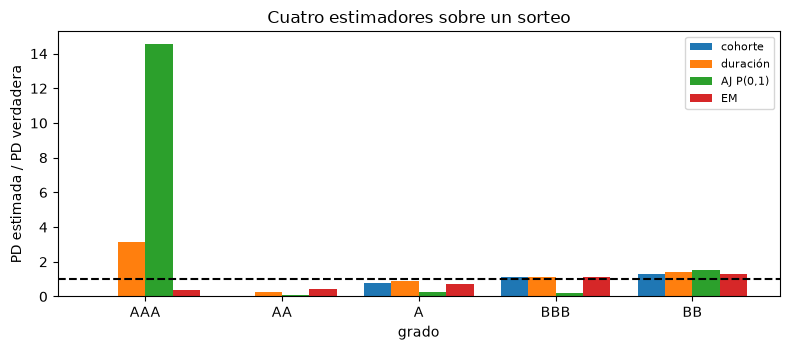

In [12]:
# Dibujar los cuatro estimadores del sorteo como múltiplos de la PD verdadera, grados AAA a BB
fig, ax = plt.subplots(figsize=(8, 3.6))
series = {"cohorte": pd_cohort, "duración": pd_dur, "AJ P(0,1)": aj01[:7, -1], "EM": pd_em}
x = np.arange(5)
for k, (name, values) in enumerate(series.items()):
    ax.bar(x + (k - 1.5) * 0.2, values[:5] / pd_true[:5], 0.2, label=name)
ax.axhline(1.0, color="black", linestyle="--")
ax.set_xticks(x)
ax.set_xticklabels(grades[:5])
ax.set_xlabel("grado")
ax.set_ylabel("PD estimada / PD verdadera")
ax.set_title("Cuatro estimadores sobre un sorteo")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

EM ve las mismas fotos anuales que el estimador de cohorte y tampoco recupera los mejores grados: devuelve PD positivas pequeñas para AAA y AA, un generador válido por construcción, pero vienen del modelo y no de saltos que haya observado. De A a BB los cuatro estimadores quedan cerca de uno, y las diferencias entre ellos son del orden del ruido de un solo sorteo. Sobre las cohortes reales de S&P, EM converge en 116 iteraciones al generador que este notebook usa como su verdad (el caso lo ajustó así), y sus PD quedan sobre las del estimador de cohorte agrupado de A a BB. La figura muestra un sorteo y no puede ordenar a los estimadores; el estudio versionado del paso siguiente sí puede.

### Paso 7: lo que dicen 200 simulaciones

Un sorteo no prueba nada sobre un estimador. El caso versiona el estudio que corrió el arnés: 200 conjuntos de datos con semilla del mismo generador, cada uno con su estimación de cohorte, de duración y EM de la PD a un año, y para cada grado el sesgo, la raíz del error cuadrático medio (RMSE) y la fracción de sorteos en que la estimación fue exactamente cero. La celda siguiente lee `markov.json` e imprime el RMSE relativo a la PD verdadera y la fracción de estimaciones nulas. Un RMSE relativo de 1 significa que el error típico es tan grande como la PD misma.

In [13]:
# Leer el estudio de 200 simulaciones: RMSE relativo y fracción de ceros
study = markov["outputs"]["rungs"][0]["estimators"]
truth = np.array(study["cohort"]["truth"])
kinds = ("cohort", "duration", "em")
relative = {k: np.array(study[k]["rmse"]) / truth for k in kinds}
zero_share = {k: [z["rate"] for z in study[k]["zero"]] for k in kinds}

print("RMSE / PD verdadera (filas: estimador, columnas: grado)")
print(f"{'':10s}" + "".join(f"{g:>9s}" for g in grades))
for k in kinds:
    print(f"{k:10s}" + "".join(f"{v:9.3f}" for v in relative[k]))
print("fracción de los 200 sorteos cuya estimación es exactamente cero")
for k in kinds:
    print(f"{k:10s}" + "".join(f"{v:9.2f}" for v in zero_share[k]))

RMSE / PD verdadera (filas: estimador, columnas: grado)
                AAA       AA        A      BBB       BB        B    CCC-C
cohort        5.609    2.184    0.529    0.386    0.227    0.114    0.098
duration      1.245    1.882    0.503    0.351    0.215    0.100    0.085
em            5.634    2.056    0.509    0.385    0.227    0.114    0.098
fracción de los 200 sorteos cuya estimación es exactamente cero
cohort         0.99     0.83     0.05     0.00     0.00     0.00     0.00
duration       0.00     0.00     0.00     0.00     0.00     0.00     0.00
em             0.00     0.00     0.00     0.00     0.00     0.00     0.00


La celda siguiente dibuja ambas tablas: el error relativo por grado en escala logarítmica, y la fracción de ceros exactos.

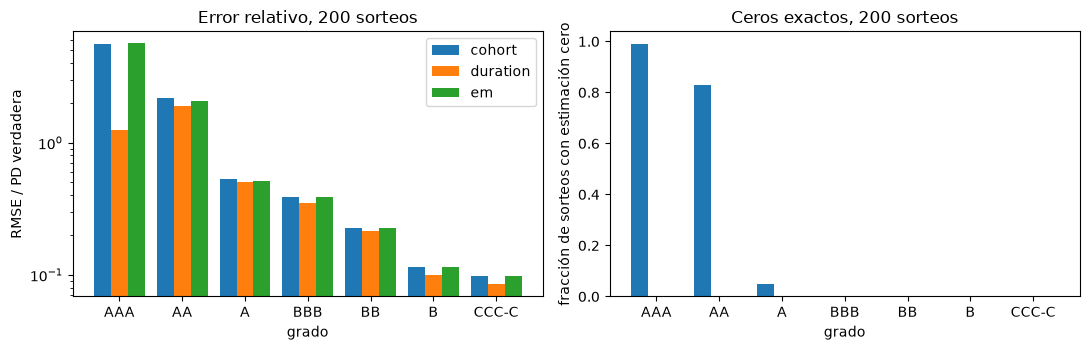

In [14]:
# Dibujar el RMSE relativo (izquierda) y la fracción de estimaciones exactamente nulas (derecha) de los tres estimadores
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.arange(7)
for k, name in enumerate(kinds):
    left.bar(x + (k - 1) * 0.27, relative[name], 0.27, label=name)
    right.bar(x + (k - 1) * 0.27, zero_share[name], 0.27, label=name)
left.set_yscale("log")
for ax in (left, right):
    ax.set_xticks(x)
    ax.set_xticklabels(grades)
    ax.set_xlabel("grado")
left.set_ylabel("RMSE / PD verdadera")
right.set_ylabel("fracción de sorteos con estimación cero")
left.set_title("Error relativo, 200 sorteos")
right.set_title("Ceros exactos, 200 sorteos")
left.legend()
fig.tight_layout()
plt.show()

El panel izquierdo dice que la elección del estimador importa donde los datos son delgados y casi nada en otros lugares: para AAA el error típico del estimador de cohorte es 5,6 veces la PD y el del estimador de duración 1,25 veces, mientras que de A a CCC-C los tres tienen errores relativos parecidos, de cerca de 0,5 en A a cerca de 0,1 en B y CCC-C. El panel derecho da la razón: en el 99% de los sorteos la estimación de cohorte de AAA es exactamente cero, y en el 83% la de AA, frente a ninguno para el estimador de duración. EM ve las mismas fotos que el estimador de cohorte y su error es el del estimador de cohorte. Lo que los paneles no muestran es el sesgo: un estimador de duración que nunca es cero aún puede ser demasiado alto, y el estudio versionado lleva esos números junto al RMSE.

### Paso 8: una segunda agencia

El mismo estimador agrupado corre sobre las cohortes de cualquier agencia. La página de transiciones de Fitch tiene una categoría de incumplimiento, así que sus 24 cohortes anuales se agrupan exactamente como las 26 de S&P; Moody's no la tiene, así que no se puede leer ninguna PD de una matriz de Moody's. La celda siguiente agrupa las tablas de Fitch con el motor y pone su PD agrupada junto a la de S&P.

In [15]:
# Agrupar las tablas de Fitch con el mismo estimador y poner su PD agrupada junto a la de S&P
fitch_cohorts = fitch["outputs"]["cohorts"]
tables_f = [np.vstack([np.array(c["counts"], dtype=float), np.zeros(len(states))]) for c in fitch_cohorts]
gone_f = [np.append(np.array(c["withdrawn"], dtype=float), 0.0) for c in fitch_cohorts]
pooled_f = estimators.pooled_cohort(tables_f, gone_f, treatment="exclude")

print(f"{'grado':8s}{'S&P':>12s}{'Fitch':>12s}{'calif. Fitch':>18s}")
for g in range(7):
    print(f"{grades[g]:8s}{100 * pooled['matrix'][g, -1]:11.3f}%"
          f"{100 * pooled_f['matrix'][g, -1]:11.3f}%{pooled_f['row_sizes'][g]:18.0f}")

grado            S&P       Fitch      calif. Fitch
AAA           0.000%      0.000%              1054
AA            0.005%      0.000%              3890
A             0.029%      0.000%             16922
BBB           0.082%      0.017%             23185
BB            0.346%      0.149%             10050
B             1.173%      0.521%              7677
CCC-C         8.068%      4.034%              1066


## Resultados

**Respuesta:** no, un grado delgado sin incumplimientos observados no tiene una PD de cero, y el estimador decide cuán lejos de cero la lee. AAA descansa en 1.895 calificaciones agrupadas y ningún incumplimiento: el intervalo de Wald tiene una cota superior de cero, Agresti-Coull de 0,244% y Jeffreys de 0,132%. En un conjunto de datos con semilla cuya PD verdadera a un año para AAA es 0,0066%, el estimador de cohorte lee 0 y el de duración 0,0204%. En 200 simulaciones la estimación de cohorte de AAA es exactamente cero en el 99% de ellas (AA: 83%) y la de duración nunca lo es, y el error del estimador de duración relativo a la PD es 1,25 para AAA frente a 5,61 del estimador de cohorte.

- **Agrupación.** Las 26 tablas anuales se agrupan en una matriz: AA descansa en un incumplimiento en 20.192 calificaciones y B en 372 en 31.712.
- **De A a CCC-C la elección importa poco.** Los errores relativos de los tres estimadores van de cerca de 0,5 en A a cerca de 0,1 en B y CCC-C, así que la elección importa donde los datos son delgados.
- **EM no recupera AAA.** El generador EM de las fotos tiene un error relativo de 5,63 para AAA, el del estimador de cohorte, y nunca devuelve cero: es siempre un generador válido, pero ve las mismas fotos anuales.
- **Aalen-Johansen** da una matriz para cualquier par de fechas sin supuesto de homogeneidad y cumple P(0, 2) = P(0, 1) P(1, 2) salvo redondeo. Sus dos años sueltos difieren porque son dos muestras de una misma cadena.
- **Conteos reales y una segunda agencia.** EM sobre las 26 cohortes reales de S&P converge en 116 iteraciones. Las PD agrupadas de Fitch son menores que las de S&P en todos los grados de AA a CCC-C, sobre 24 cohortes frente a 26.

Lo que este notebook no muestra: si el generador existe y qué reparación usar (notebook 03), si el supuesto de Markov se cumple (notebook 04), ni cómo la definición de incumplimiento y las retiradas sesgan una PD (notebook 10).

## Resumen

- El estimador de cohorte agrupa fotos anuales y no ve nada de lo que ocurre dentro del año; el de duración usa cada salto y el tiempo en cada grado; Aalen-Johansen abandona la homogeneidad en el tiempo; EM halla un generador válido solo desde fotos.
- En un grado delgado el estimador de cohorte devuelve exactamente cero la mayor parte del tiempo y el intervalo de Wald tiene ancho cero; el estimador de duración y el intervalo de Jeffreys no.
- Los estimadores se comparan sobre datos cuya verdad se conoce, en muchos sorteos, nunca sobre una sola muestra.
- Las cohortes de una segunda agencia se agrupan con la misma llamada, y las diferencias entre agencias se ven en las PD agrupadas.

**Qué probar después.** Cambia la semilla del sorteo del Paso 3 y mira moverse las estimaciones de AAA; luego lee el notebook 03 sobre el problema de inmersión.

## Referencias

- ESMA, publicación CEREP de calificaciones y transiciones de agencias calificadoras. https://registers.esma.europa.eu/cerep-publication/
- Anderson, T. W. y Goodman, L. A. (1957), Statistical inference about Markov chains, Annals of Mathematical Statistics 28(1), ecuaciones 2.8 y 2.9. https://doi.org/10.1214/aoms/1177707039
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- Schuermann, T. y Hanson, S. (2004), Estimating probabilities of default, FRBNY Staff Report 190. https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr190.pdf
- Lando, D. y Skodeberg, T. M. (2002), Analyzing rating transitions and rating drift with continuous observations, Journal of Banking and Finance 26(2-3), doi 10.1016/S0378-4266(01)00228-X.
- Aalen, O. O. y Johansen, S. (1978), An empirical transition matrix for non-homogeneous Markov chains based on censored observations, Scandinavian Journal of Statistics 5(3), 141-150.
- Bladt, M. y Sorensen, M. (2005), Statistical inference for discretely observed Markov jump processes, Journal of the Royal Statistical Society B 67(3), y Smith, A. y dos Reis, G. (2018), Quantitative Finance, doi 10.1080/14697688.2017.1383627.